## Plan

- **Задача:** знайти природні групи в наборі Wine без використання міток сорту.
- **Гіпотеза:** у даних є 3 групи, бо в наборі 3 сорти. На масштабованих ознаках K-means їх знайде, а без масштабування результат буде гіршим, бо proline має значення в сотнях і переважатиме інші ознаки.
- **Базова лінія:** k = 3; контрольний варіант — K-means на немасштабованих ознаках.
- **Первинна метрика:** silhouette і його стабільність за 5 різними random_state; ARI зі справжніми сортами як зовнішня перевірка.
- **Критерій прийняття:** silhouette > 0.25, ARI > 0.7, розкид silhouette і ARI за 5 random_state < 0.05, ARI на масштабованих ознаках вищий, ніж на немасштабованих.

## Етап 1. Підготовка середовища та завантаження даних

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)
y_true = data.target

## Етап 2. Дослідницький аналіз даних (EDA)

In [3]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


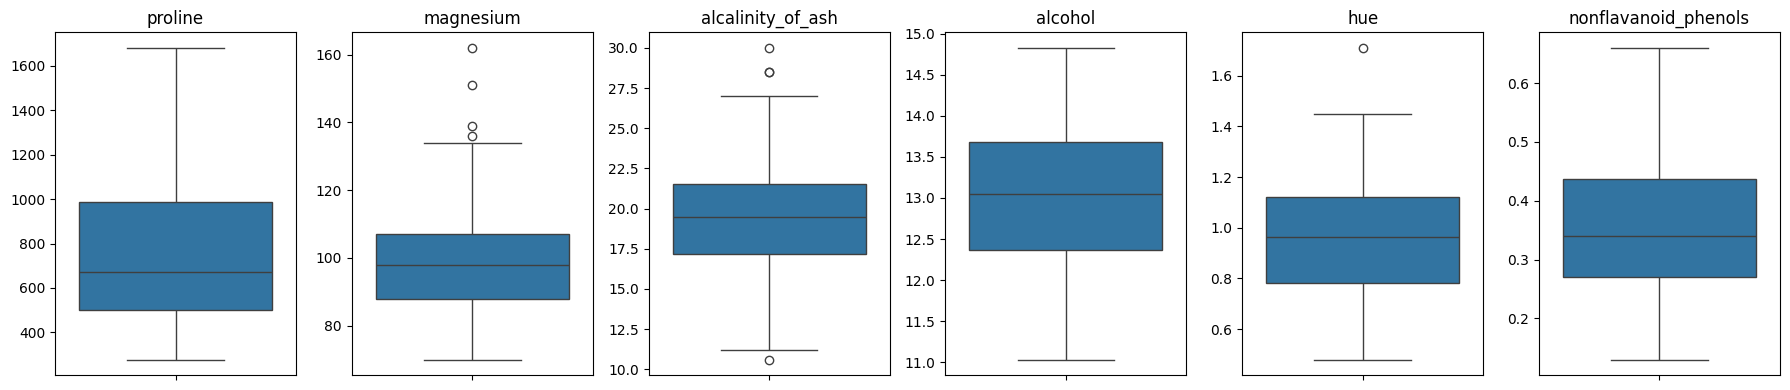

In [4]:
features = ['proline', 'magnesium', 'alcalinity_of_ash', 'alcohol', 'hue', 'nonflavanoid_phenols']

fig, axes = plt.subplots(1, 6, figsize=(18, 4))
for ax, feature in zip(axes, features):
    sns.boxplot(y=df[feature], ax=ax)
    ax.set_title(feature)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

## Етап 3. Масштабування ознак

In [5]:
X = df.values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Етап 4. Метод головних компонент (PCA)

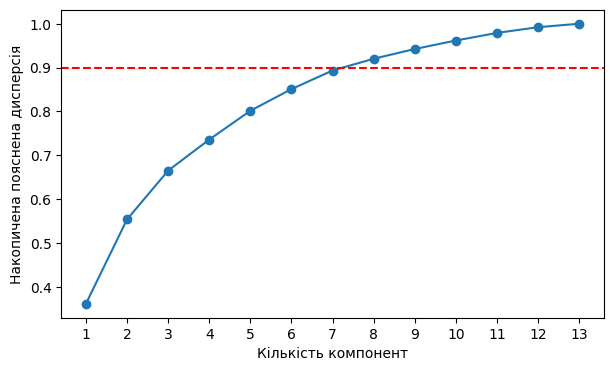

[0.362  0.5541 0.6653 0.736  0.8016 0.851  0.8934 0.9202 0.9424 0.9617
 0.9791 0.992  1.    ]
Компонент для 90%: 8


In [6]:
pca = PCA()
pca.fit(X_scaled)
cumulative = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative) + 1), cumulative, marker='o')
plt.axhline(0.9, color='red', linestyle='--')
plt.xticks(range(1, len(cumulative) + 1))
plt.xlabel('Кількість компонент')
plt.ylabel('Накопичена пояснена дисперсія')
plt.show()

print(cumulative.round(4))
print('Компонент для 90%:', np.argmax(cumulative >= 0.9) + 1)

[0.362  0.1921] 0.5541


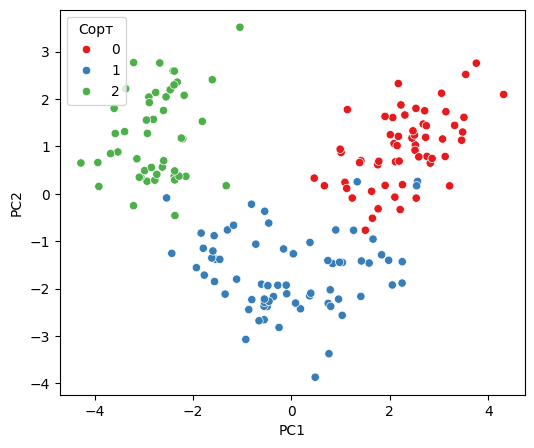

In [7]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)
print(pca_2d.explained_variance_ratio_.round(4), pca_2d.explained_variance_ratio_.sum().round(4))

plt.figure(figsize=(6, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true, palette='Set1')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Сорт')
plt.show()

## Етап 5. Кластеризація методом K-means

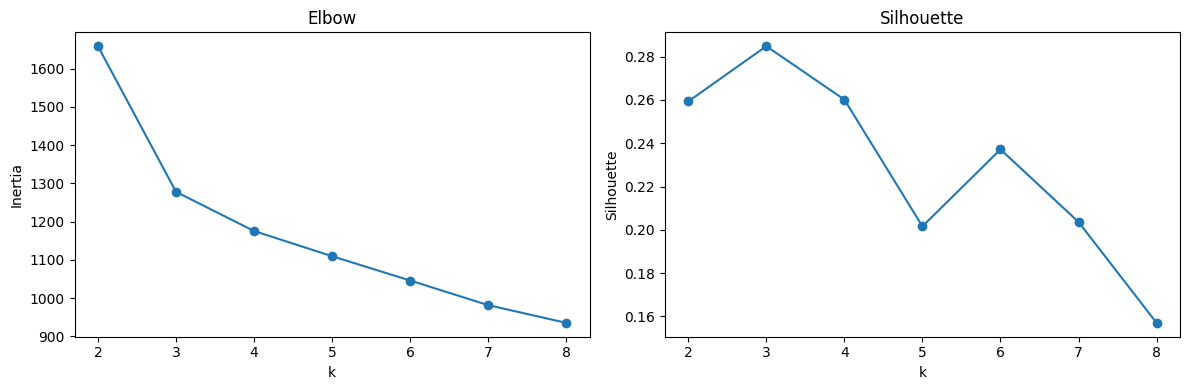

In [8]:
k_values = range(2, 9)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker='o')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow')
axes[1].plot(k_values, silhouettes, marker='o')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette')
axes[1].set_title('Silhouette')
plt.tight_layout()
plt.show()

In [9]:
k = 3
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
kmeans.fit(X_scaled)
labels = kmeans.labels_

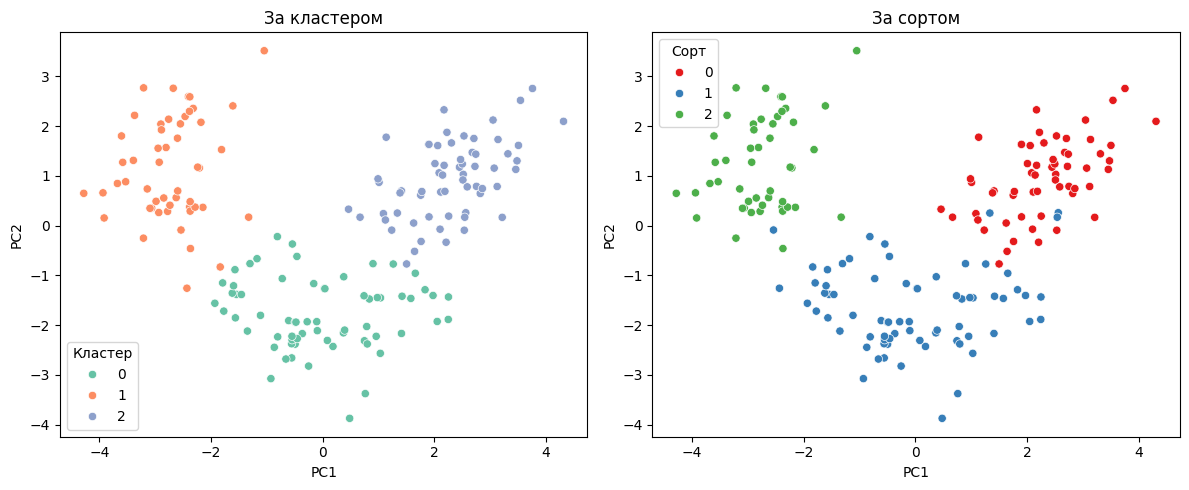

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette='Set2', ax=axes[0])
axes[0].set_title('За кластером')
axes[0].legend(title='Кластер')
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true, palette='Set1', ax=axes[1])
axes[1].set_title('За сортом')
axes[1].legend(title='Сорт')
for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

## Етап 6. Оцінювання, стабільність і чутливість до масштабу

In [11]:
sil_scaled = silhouette_score(X_scaled, labels)
ari_scaled = adjusted_rand_score(y_true, labels)
print('Silhouette:', round(sil_scaled, 4))
print('ARI:', round(ari_scaled, 4))

Silhouette: 0.2849
ARI: 0.8975


In [12]:
seeds = [0, 1, 2, 3, 4]
stability = []

for seed in seeds:
    km = KMeans(n_clusters=k, n_init=10, random_state=seed)
    km.fit(X_scaled)
    stability.append({
        'random_state': seed,
        'silhouette': silhouette_score(X_scaled, km.labels_),
        'ARI': adjusted_rand_score(y_true, km.labels_),
    })

stability = pd.DataFrame(stability).set_index('random_state')
spread = stability.max() - stability.min()
print(stability.round(4))
print('Розкид:')
print(spread.round(4).to_string())

              silhouette     ARI
random_state                    
0                 0.2849  0.8975
1                 0.2849  0.8975
2                 0.2849  0.8975
3                 0.2849  0.8975
4                 0.2849  0.8975
Розкид:
silhouette    0.0
ARI           0.0


In [13]:
kmeans_raw = KMeans(n_clusters=k, n_init=10, random_state=42)
kmeans_raw.fit(X)
labels_raw = kmeans_raw.labels_

sil_raw = silhouette_score(X, labels_raw)
ari_raw = adjusted_rand_score(y_true, labels_raw)
print('Silhouette (немасштабовані):', round(sil_raw, 4))
print('ARI (немасштабовані):', round(ari_raw, 4))

Silhouette (немасштабовані): 0.5711
ARI (немасштабовані): 0.3711


In [14]:
print('Розміри кластерів (масштабовані):', np.bincount(labels))
print('Розміри кластерів (немасштабовані):', np.bincount(labels_raw))

distances = kmeans.transform(X_scaled).min(axis=1)
q1, q3 = np.percentile(distances, [25, 75])
threshold = q3 + 1.5 * (q3 - q1)
outliers = np.where(distances > threshold)[0]
print('Поріг відстані до центроїда:', round(threshold, 4))
print('Викиди:', outliers)

Розміри кластерів (масштабовані): [65 51 62]
Розміри кластерів (немасштабовані): [62 47 69]
Поріг відстані до центроїда: 4.4482
Викиди: [ 59  69  73  95 110 121 158]


## Етап 7. Аналіз та висновки

In [15]:
summary = pd.DataFrame({
    'Ознаки': ['масштабовані', 'немасштабовані'],
    'k': [k, k],
    'Silhouette': [sil_scaled, sil_raw],
    'ARI': [ari_scaled, ari_raw],
    'Розміри кластерів': [sorted(np.bincount(labels), reverse=True), sorted(np.bincount(labels_raw), reverse=True)],
}).round(4)
summary

,Ознаки,k,Silhouette,ARI,Розміри кластерів
0,масштабовані,3,0.2849,0.8975,"[65, 62, 51]"
1,немасштабовані,3,0.5711,0.3711,"[69, 62, 47]"


In [16]:
pd.Series({
    'silhouette > 0.25': sil_scaled > 0.25,
    'ARI > 0.7': ari_scaled > 0.7,
    'розкид silhouette < 0.05': spread['silhouette'] < 0.05,
    'розкид ARI < 0.05': spread['ARI'] < 0.05,
    'ARI масштабовані > ARI немасштабовані': ari_scaled > ari_raw,
})

silhouette > 0.25                        True
ARI > 0.7                                True
розкид silhouette < 0.05                 True
розкид ARI < 0.05                        True
ARI масштабовані > ARI немасштабовані    True
dtype: bool